<a href="https://colab.research.google.com/github/Luthfi-collab/Repo-pm-turi4-clustering/blob/main/Praktikum9_Clustering_KMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 9 — Clustering dengan K-Means
**Mata Kuliah:** Pembelajaran Mesin

**Nama:** Luthfi Baihaqi  **NIM:** 2488010036  **Kelas:** Informatika 5C

### Tujuan
1. Menyiapkan data tanpa label untuk clustering (termasuk scaling).
2. Menentukan jumlah cluster optimal dengan metode Elbow.
3. Menerapkan K-Means dan memvisualisasikan hasilnya.
4. Mengevaluasi clustering dengan silhouette score.
5. Menafsirkan makna tiap cluster (segmentasi pelanggan).

## Persiapan: Dataset Segmentasi Pelanggan (data buatan)
Dataset dibuat secara sintetis berisi 300 pelanggan dengan tiga fitur: usia (tahun), pendapatan (juta rupiah per tahun), dan skor_belanja (1–100). Tidak ada kolom label, ini adalah data unsupervised.

In [6]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

def buat_kelompok(n, usia, pendapatan, skor):
    return pd.DataFrame({
        'usia':         rng.normal(usia[0], usia[1], n),
        'pendapatan':   rng.normal(pendapatan[0], pendapatan[1], n),
        'skor_belanja': rng.normal(skor[0], skor[1], n),
    })

df = pd.concat([
    buat_kelompok(100, (25, 4),  (120, 25), (80, 8)),   # muda, pendapatan menengah, belanja tinggi
    buat_kelompok(100, (45, 5),  (280, 35), (30, 8)),   # paruh baya, pendapatan tinggi, belanja rendah
    buat_kelompok(100, (58, 5),  (60, 15),  (50, 8)),   # senior, pendapatan rendah, belanja sedang
], ignore_index=True)

df['usia'] = df['usia'].clip(18, 75).round(0)
df['pendapatan'] = df['pendapatan'].clip(20, None).round(1)
df['skor_belanja'] = df['skor_belanja'].clip(1, 100).round(0)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)   # acak urutan baris

print(df.shape)
print(df.head())
print()
print(df.describe().round(1))

(300, 3)
   usia  pendapatan  skor_belanja
0  55.0        59.1          53.0
1  50.0        61.3          39.0
2  42.0       348.3          32.0
3  22.0        76.8          77.0
4  48.0        57.2          47.0

        usia  pendapatan  skor_belanja
count  300.0       300.0         300.0
mean    42.6       152.9          52.5
std     14.2        95.7          22.2
min     18.0        25.8           6.0
25%     27.0        70.9          34.0
50%     46.0       116.8          49.0
75%     54.2       256.5          74.0
max     71.0       370.9         100.0


## Langkah 1 — Menyiapkan data & scaling (wajib)

In [7]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
# df berisi usia, pendapatan, skor_belanja (tanpa label)
X_scaled = StandardScaler().fit_transform(df)
print("Rata-rata tiap fitur setelah scaling:", X_scaled.mean(axis=0).round(3))
print("Std tiap fitur setelah scaling      :", X_scaled.std(axis=0).round(3))

Rata-rata tiap fitur setelah scaling: [-0. -0.  0.]
Std tiap fitur setelah scaling      : [1. 1. 1.]


## Langkah 2 — Metode Elbow menentukan K

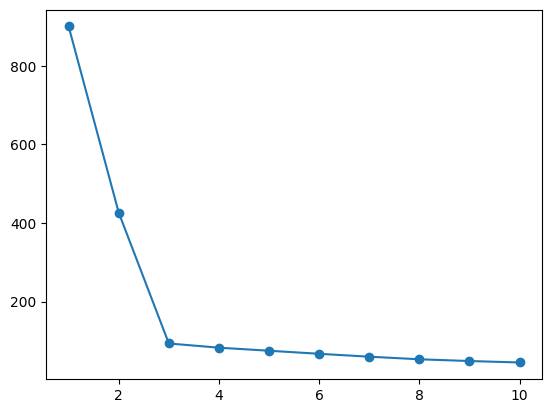

In [8]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()

## Langkah 3 — Menjalankan K-Means (K=3)

In [9]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
2    100
1    100
0    100
Name: count, dtype: int64


## Langkah 4 — Evaluasi silhouette score

In [10]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.7279349517130232


## Langkah 5 — Interpretasi: profil rata-rata tiap cluster

In [11]:
profil = df.groupby('cluster')[['usia','pendapatan', 'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil


         usia  pendapatan  skor_belanja
cluster                                
0        24.8       119.7          79.5
1        45.5       278.4          29.3
2        57.4        60.6          48.7


---
## D. Latihan Mandiri
### 6.	Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [ ]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
label_k5 = km5.fit_predict(X_scaled)
sil_k5 = silhouette_score(X_scaled, label_k5)

print(f"Silhouette K=3 : {sil_k3:.4f}")
print(f"Silhouette K=5 : {sil_k5:.4f}")
print("Selisih (K=3 - K=5):", round(sil_k3 - sil_k5, 4))
print("\nJumlah anggota K=5:", np.bincount(label_k5))

Silhouette K=3 : 0.7279
Silhouette K=5 : 0.4117
Selisih (K=3 - K=5): 0.3162

Jumlah anggota K=5: [ 41  59 100  59  41]


Hasil: silhouette K=3 = 0,728 dan K=5 = 0,412 (selisih ± 0,32).

Analisis: K=3 jauh lebih baik. Data sebenarnya hanya memiliki tiga kelompok alami, sehingga pada K=5 K-Means terpaksa *memecah* kelompok yang utuh menjadi bagian-bagian kecil (anggota K=5: 41, 59, 100, 59, 41). Pecahan itu saling berdekatan sehingga jarak antar-cluster mengecil dan silhouette turun. Ini juga mengonfirmasi pilihan K=3 dari metode Elbow. Catatan: pemecahan seperti ini membuat segmen tidak bermakna secara bisnis.

### 7.	Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

In [ ]:
km_ns = KMeans(n_clusters=3, random_state=42, n_init=10)
label_ns = km_ns.fit_predict(df[['usia', 'pendapatan', 'skor_belanja']])   # data mentah, tanpa scaling

# Silhouette dihitung pada ruang fitur masing-masing model
sil_ns_raw = silhouette_score(df[['usia', 'pendapatan', 'skor_belanja']], label_ns)
# Untuk perbandingan yang adil, label tanpa-scaling juga dinilai di ruang ter-scaling
sil_ns_scaled_space = silhouette_score(X_scaled, label_ns)

print(f"Silhouette dengan scaling (K=3)                     : {sil_k3:.4f}")
print(f"Silhouette tanpa scaling (dihitung di data mentah)  : {sil_ns_raw:.4f}")
print(f"Silhouette tanpa scaling (dinilai di ruang scaled)  : {sil_ns_scaled_space:.4f}")

from sklearn.metrics import adjusted_rand_score
print("\nKesamaan pengelompokan scaled vs tanpa-scaling (ARI):",
      round(adjusted_rand_score(df['cluster'], label_ns), 4))

# Mengapa dampaknya kecil di sini? Lihat porsi variansi tiap fitur pada data mentah:
var = df[['usia', 'pendapatan', 'skor_belanja']].var()
print("\nPorsi variansi tiap fitur di data mentah (yang menentukan jarak Euclidean):")
print((var / var.sum() * 100).round(1).astype(str) + ' %')

print("\nProfil rata-rata cluster TANPA scaling:")
print(df.assign(cluster_ns=label_ns).groupby('cluster_ns')[['usia', 'pendapatan', 'skor_belanja']].mean().round(1))

Silhouette dengan scaling (K=3)                     : 0.7279
Silhouette tanpa scaling (dihitung di data mentah)  : 0.6715
Silhouette tanpa scaling (dinilai di ruang scaled)  : 0.7213

Kesamaan pengelompokan scaled vs tanpa-scaling (ARI): 0.99

Porsi variansi tiap fitur di data mentah (yang menentukan jarak Euclidean):
usia             2.1 %
pendapatan      92.9 %
skor_belanja     5.0 %
dtype: str

Profil rata-rata cluster TANPA scaling:
            usia  pendapatan  skor_belanja
cluster_ns                                
0           24.9       120.3          79.6
1           45.5       278.4          29.3
2           57.1        60.6          48.8


Hasil: silhouette tanpa scaling (dihitung di data mentah) = 0,672, sedangkan dengan scaling = 0,728. Pengelompokan keduanya hampir identik (ARI = 0,99) dan silhouette label tanpa-scaling bila dinilai di ruang ter-scaling adalah 0,721.

Kesimpulan:
1. Angka silhouette 0,672 vs 0,728 tidak sepenuhnya sebanding, karena dihitung pada ruang jarak yang berbeda. Pembandingan yang lebih adil adalah ARI dan silhouette di ruang yang sama.
2. Pada dataset ini dampak visualnya kecil karena ketiga kelompok sangat terpisah pada pendapatan, fitur yang mendominasi jarak (±93% variansi data mentah). Tanpa scaling, K-Means pada dasarnya hanya "melihat" pendapatan, dan kebetulan itu sudah cukup memisahkan ketiga kelompok.
3. Pada data nyata, kelompok sering dibedakan oleh banyak fitur sekaligus. Di situ fitur berskala besar akan menenggelamkan usia dan skor_belanja, sehingga hasil cluster menjadi bias dan menyesatkan. Scaling tetap wajib pada algoritma berbasis jarak seperti K-Means; tidak adanya perbedaan di sini adalah kebetulan karena karakter data sintetis ini, bukan alasan untuk melewatkannya.

### 8.	Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

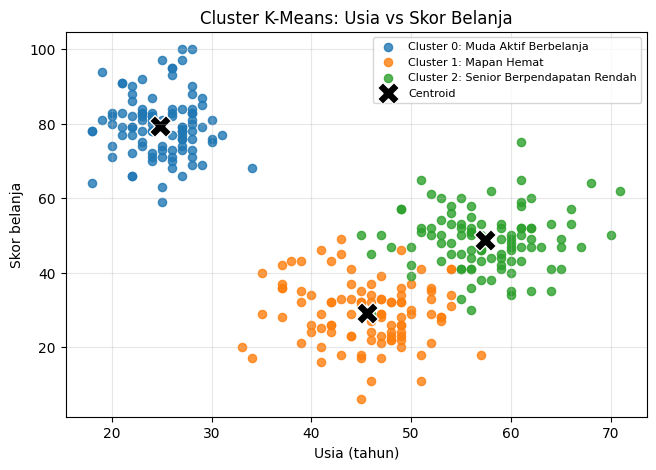

In [ ]:
plt.figure(figsize=(7.5, 5))
for c in range(3):
    sub = df[df['cluster'] == c]
    plt.scatter(sub['usia'], sub['skor_belanja'], s=35, alpha=0.8, color=warna[c], label=f"Cluster {c}: {nama_cluster[c]}")

# centroid (dikembalikan ke skala asli)
pusat = pd.DataFrame(StandardScaler().fit(df[['usia', 'pendapatan', 'skor_belanja']]).inverse_transform(kmeans.cluster_centers_),
                     columns=['usia', 'pendapatan', 'skor_belanja'])
plt.scatter(pusat['usia'], pusat['skor_belanja'], marker='X', s=250, c='black', edgecolor='white', label='Centroid')

plt.xlabel('Usia (tahun)'); plt.ylabel('Skor belanja')
plt.title('Cluster K-Means: Usia vs Skor Belanja')
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

---
## E. Refleksi
1. Bagaimana K-Means menemukan kelompok tanpa label?
K-Means tidak memerlukan label karena hanya memakai kemiripan (jarak) antar titik. Prosesnya: (1) pilih K centroid awal secara acak; (2) assignment setiap titik masuk ke centroid terdekat; (3) update tiap centroid dipindah ke rata-rata anggotanya; (4) ulangi langkah 2–3 hingga centroid tidak berubah (konvergen). Tujuannya meminimalkan inertia, yaitu jumlah kuadrat jarak titik ke centroid-nya. Karena titik yang berdekatan cenderung berkumpul di sekitar centroid yang sama, struktur kelompok muncul dengan sendirinya. Makna kelompok baru kita beri sendiri setelah melihat profilnya.

2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?
Inertia turun drastis dari 900 (K=1) > 426 (K=2) > 93 (K=3), karena setiap penambahan cluster sampai K=3 memisahkan kelompok nyata yang sebelumnya tergabung. Setelah K=3, penurunan hanya sekitar 7–10 per langkah (93 > 83 > 75 > …) karena cluster tambahan hanya memecah kelompok yang sudah kompak. Hal ini terjadi karena data dibangkitkan dari tiga kelompok, jadi struktur alaminya memang tiga.

3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?
K-Means memakai jarak Euclidean, sehingga fitur dengan satuan/rentang besar (pendapatan: puluhan–ratusan) mendominasi fitur berskala kecil (usia, skor). Tanpa scaling, cluster praktis ditentukan oleh fitur terbesar dan informasi fitur lain hilang; hasil juga berubah bila satuan diganti (mis. juta > rupiah). Pada data ini, pendapatan menyumbang 93% variansi sehingga tanpa scaling hampir hanya pendapatan yang berperan. Hasilnya kebetulan masih mirip (ARI 0,99) karena kelompok sangat terpisah pada pendapatan kondisi yang tidak bisa diandalkan pada data nyata.

---
## Kesimpulan
- Data tanpa label di-scale dengan StandardScaler karena K-Means berbasis jarak.
- Metode Elbow menunjukkan siku pada K = 3; K-Means (K=3) menghasilkan tiga cluster berukuran seimbang (100 anggota tiap cluster) dengan silhouette score 0,728 (cluster padat dan terpisah baik).
- K=5 menurunkan silhouette menjadi 0,412 karena memecah kelompok alami; K=3 terbukti lebih baik.
- Tiga segmen pelanggan: Muda Aktif Berbelanja, Mapan Hemat, dan Senior Berpendapatan Rendah, masing-masing dengan strategi pemasaran yang berbeda.
- Pada dataset ini scaling tidak mengubah hasil secara drastis karena kelompok sangat terpisah pada pendapatan, tetapi secara prinsip scaling tetap wajib.
- Keterbatasan: data bersifat sintetis dan rapi, sehingga hasilnya lebih bersih daripada data pelanggan sebenarnya.